# Wave-following average-- Winds, precipitation, and moisture
This notebook produces wave-following averages of several fields, using the wavetracks from QTRACK. Select the wave in question (whether Paulette 'second', or Rene 'main'). 
Plots for a selected ensemble set, whether fluxon, fluxoff, rst_on24, 
rst_on36, or rst_on48. 

In [1]:
import pkg_resources
from __future__ import print_function
from datetime import datetime, timedelta

import numpy as np
import xarray as xr
import pandas as pd
import os
import glob
from netCDF4 import Dataset, num2date, date2num

#from AEW_module import season, AEW, AEW_CCKW

from metpy.units import units
import geocat.viz as gv


import metpy

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.ticker as mticker 

import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import wrf
from wrf import (to_np, interplevel, geo_bounds, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, destagger)

import seaborn as sns
import metpy.calc as mpcalc

/glade/derecho/scratch/athornton/tmp/ipykernel_96994/2373823758.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
plotsdir = '/glade/u/home/athornton/qtrack/'

In [3]:
## The following are lists to select each ensemble set and respective initialization time
variation = ['fluxon', 'rst_on24', 'rst_on36', 'rst_on48', '', 'fluxoff', '', '', '']
init_times = ['0300','0303','0306',
             '0309','0312','0315',
             '0318','0321','0400']

In [14]:
#########################################
### MAKE SELECTIONS HERE
#set = 'Fluxes on'          # try: '24 hours without fluxes'
set_name = variation[5]     # try: variation[1]
wave = 'main'             # 'second' == Paulette or 'main' == Rene
title = 'Fluxes off'  # What will be displayed on main plot

In [15]:
# From Anantha...
# Simple linear interpolation between each latitude point
def get_lats():
    new_lats = []
    wave_track_lats = df.lat[-len(times_list_6hr):]
    for i in range(0,len(wave_track_lats)):
        if wave_track_lats[i] == wave_track_lats[-1]:
            new_lats.append(wave_track_lats[i].values)
        else:
            next_value = 0.5*(wave_track_lats[i] + wave_track_lats[i+1])
            new_lats.append(wave_track_lats[i].values)
            new_lats.append(next_value.values)
    return new_lats

# Simple linear interpolation between each longitude point
def get_lons():
    new_lons = []
    wave_track_lons = df.lon[-len(times_list_6hr):] 
    for i in range(0,len(wave_track_lons)):
        if wave_track_lons[i] == wave_track_lons[-1]:
            new_lons.append(wave_track_lons[i].values)
        else:
            next_value = 0.5*(wave_track_lons[i] + wave_track_lons[i+1])
            new_lons.append(wave_track_lons[i].values)
            new_lons.append(next_value.values)
    return new_lons

In [16]:
def mass_weighted_vert_integral(height, data):
    # data is expected to be on pressure levels
    levels = height[0,:,0,0]#.metpy.convert_units('Pa')
#    print(levels)
    deltaP = (levels - levels.shift(bottom_top=-1))#.metpy.convert_units('Pa')
#    print(deltaP)
    vert_int_data = ((data.shift(bottom_top=-1)+data)*.5*deltaP).sum(dim='bottom_top') / metpy.constants.earth_gravity    
    return  vert_int_data

In [17]:
# wrf_out_data = xr.open_dataset(datafiles[0])  
# pb = wrf_out_data['PB'].metpy.quantify()

fluxoff_0300
53
./wrfout_d01_2020-09-03_00:00:00
WRF valid time:  2020-09-03_00:00
WRF valid time:  2020-09-03_03:00
WRF valid time:  2020-09-03_06:00
WRF valid time:  2020-09-03_09:00
WRF valid time:  2020-09-03_12:00
WRF valid time:  2020-09-03_15:00
WRF valid time:  2020-09-03_18:00
WRF valid time:  2020-09-03_21:00
WRF valid time:  2020-09-04_00:00
WRF valid time:  2020-09-04_03:00
WRF valid time:  2020-09-04_06:00
WRF valid time:  2020-09-04_09:00
WRF valid time:  2020-09-04_12:00
WRF valid time:  2020-09-04_15:00
WRF valid time:  2020-09-04_18:00
WRF valid time:  2020-09-04_21:00
WRF valid time:  2020-09-05_00:00
WRF valid time:  2020-09-05_03:00
WRF valid time:  2020-09-05_06:00
WRF valid time:  2020-09-05_09:00
WRF valid time:  2020-09-05_12:00
WRF valid time:  2020-09-05_15:00
WRF valid time:  2020-09-05_18:00
WRF valid time:  2020-09-05_21:00
WRF valid time:  2020-09-06_00:00
WRF valid time:  2020-09-06_03:00
WRF valid time:  2020-09-06_06:00
WRF valid time:  2020-09-06_09:00

/glade/derecho/scratch/athornton/tmp/ipykernel_96994/1400103630.py:169: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(loc='lower right')


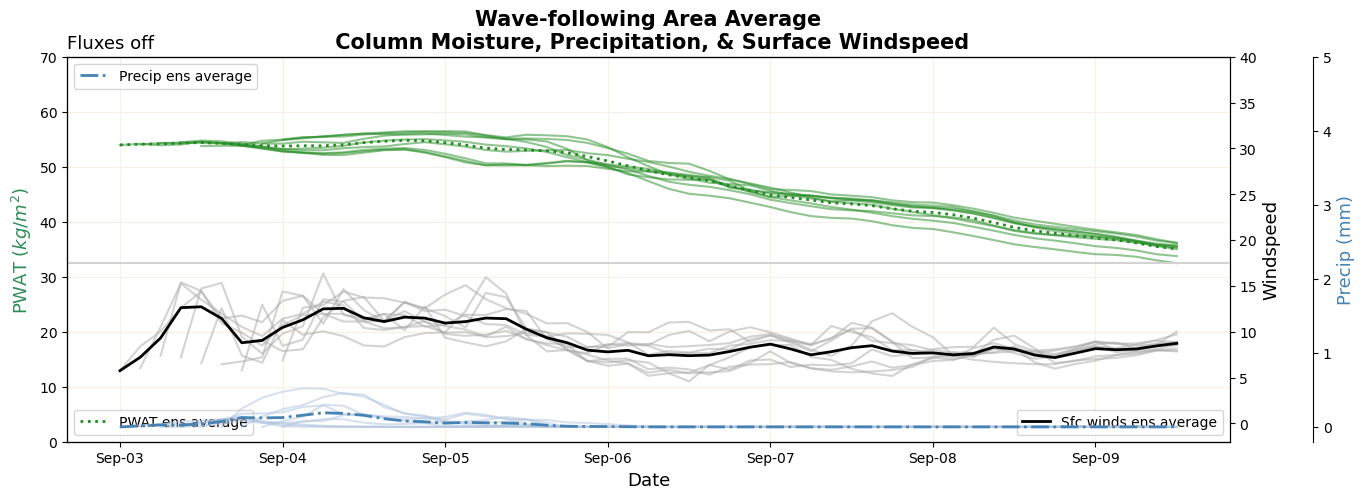

In [18]:
# Set up loop to run same plots for multiple different times (assume here that we have 1 time per wrfout file)
plt.rcParams['savefig.dpi'] = 255

fig, ax = plt.subplots(figsize=(15,5))

ax.set_title('Wave-following Area Average\n Column Moisture, Precipitation, & Surface Windspeed', size=15, weight='bold')
plt.title(title, loc='left', size=13)
ax.set_ylabel('$1/s$', size =13)
ax.set_xlabel('Date', size=13)
date_form = DateFormatter('%b-%d')
ax.xaxis.set_major_formatter(date_form)
# column moisture
ax.set_ylim(0,70)

# surface windspeed
ax2=ax.twinx()
ax2.set_ylim(-2,40)

# precipitation
ax3=ax.twinx()
ax3.set_ylim(-0.2,5)


winds_list_tot = []
moist_list_tot = []
rain_list_tot = []

for init_time in init_times:
    save_name = set_name +"_"+ init_time
    print(save_name)
    # get wavetrack data
    df = xr.open_dataset('/glade/u/home/athornton/qtrack/'+wave+'_wave/'+wave+'_wave_track_'+save_name+'.nc')

    # get wrfout data
    os.chdir("/glade/campaign/univ/uncs0067/flux_experiments/cent_atl_case/init"+init_time+"z/"+set_name+"/")
    datafiles = sorted(glob.glob("./wrfout*"))
    numfiles=len(datafiles)
    # select every other file to match wave-track resolution
    print(numfiles)
    print(datafiles[0])
    start_time ='2020-09-'+init_time[:2]+' '+init_time[2:]+':00'
    times_list_6hr = pd.date_range(start=start_time, end='2020-09-09 12:00', freq='6h')
    times_list = pd.date_range(start=start_time, end='2020-09-09 12:00', freq='3h')
    # select lons, lats in the window of our simulation time
    wave_track_lats = get_lats()
    wave_track_lons = get_lons()
    wrf_out_data = xr.open_dataset(datafiles[0])  
    pb = wrf_out_data['PB'].metpy.quantify()
    
    winds_list = []
    moist_list = []
    for i in range(0,len(datafiles)):
        ncfile = Dataset(datafiles[i])
        Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
        timestr=(str(Time))
        # Set up one time string for plot titles, another for file names
        titletime=(timestr[0:10]+' '+timestr[11:16])
        filetime=(timestr[0:10]+'_'+timestr[11:16])
        print('WRF valid time: ',filetime)
    
        wrf_out_data = xr.open_dataset(datafiles[i])  
        
        # Get all the variables we need
        qwv = wrf_out_data["QVAPOR"].metpy.quantify()
        ua = wrf_out_data["U"]
        va = wrf_out_data["V"]
    
        lats, lons = latlon_coords(wrf_out_data['P'])
        lats_np = to_np(lats)
        lons_np = to_np(lons)
        lats_np = lats_np[0,:,0]
        lons_np = lons_np[0,0,:]
        
        # Unstagger the winds to match the pressure grid
        ua = destagger(ua, stagger_dim=3)             # Unstagger U in the x-direction
        va = destagger(va, stagger_dim=2)             # Unstagger V in the x-direction
    
        # Grid spacing for vorticity calculation
        dx = ncfile.DX * units("m")
        dy = ncfile.DY * units("m")
        
        u_winds = xr.DataArray(ua)[0]
        v_winds = xr.DataArray(va)[0]
        qwv =  xr.DataArray(qwv)[0]
        
        u_sfc = u_winds.sel(dim_1=1)*units('m/s')     # select surface winds
        v_sfc = v_winds.sel(dim_1=1)*units('m/s')     # select surface winds
        wind_sfc = mpcalc.wind_speed(u_sfc, v_sfc)

        try:
            lat_lon = [wave_track_lats[i],wave_track_lons[i]]     # Lat, Lon cooridante of center of square we are interested in
        except IndexError:
            lat_lon = [wave_track_lats[i-1],wave_track_lons[i-1]] # if the last datapoint does not have a track, keep the datapoint from before
                      
        
        x_ycenter = wrf.ll_to_xy(ncfile, lat_lon[0], lat_lon[1])
    
        # specify how big you want the wave-following box to be
        delta = 50                             # in grid points 
    
        winds = wind_sfc[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)]
    
        # wave tracks have nans at the beginning so return nan if it's the beginning of the track
        if not winds.any():
            max_wind = np.nan
        else:
            max_wind = np.max(winds.values)
    
        columnq = mass_weighted_vert_integral(pb, qwv)
        avg_qwv = columnq[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)].mean()
    
        winds_list.append(max_wind)
        moist_list.append(avg_qwv.values)
        
    # Column moisture
    df=pd.DataFrame(moist_list)
    df['date']=times_list
    df=df.set_index('date')
    moist_list_tot.append(df)

    # Surface windspeed
    df2=pd.DataFrame(winds_list)
    df2['date']=times_list
    df2=df2.set_index('date')
    winds_list_tot.append(df2)
    
    # Precipitation
    data = xr.open_mfdataset(datafiles, concat_dim='Time', combine='nested', engine='netcdf4')
    rain = data.RAINC
    time = data.XTIME.compute()
    rain_list = [np.zeros_like(rain[0])]  # Start with a zero array for the first time step

    for i in range(1, len(rain)):
        rain_hour = rain[i] - rain[i-1]
        rain_hour = np.maximum(rain_hour, 0)  # Set negative values to 0
        rain_list.append(rain_hour)

    rain = xr.DataArray(rain_list)

    # Apply wavetrack to this rain data and only choose points within our wave-following box
    rain_box_list = []
    for i in range(0,len(datafiles)):
        try:
            lat_lon = [wave_track_lats[i],wave_track_lons[i]]                 # Lat, Lon cooridante of center of square we are interested in
        except IndexError:
            lat_lon = [wave_track_lats[i-1],wave_track_lons[i-1]] # if the last datapoint does not have a track, keep the datapoint from before
        
        x_ycenter = wrf.ll_to_xy(ncfile, lat_lon[0], lat_lon[1])
    
        # specify how big you want the wave-following box to be
        delta = 50                                # in grid points 
        rain_inc = rain[i]
        rain_box = rain_inc[int(x_ycenter[1]-delta):int(x_ycenter[1]+delta),int(x_ycenter[0]-delta):int(x_ycenter[0]+delta)].mean()
        rain_box_list.append(rain_box)
    precip_array = np.array(rain_box_list)

    df3=pd.DataFrame(precip_array)
    df3['date']=times_list
    df3=df3.set_index('date')
    rain_list_tot.append(df3)

    ax.plot(times_list, moist_list, color='forestgreen', alpha=0.5)
    ax2.plot(times_list, winds_list, color='darkgray', alpha=0.5)
    ax3.plot(times_list, precip_array, color='lightsteelblue', alpha=0.5)

ax.set_ylabel('PWAT ($kg/m^2$)', size=13, color='seagreen')
    
ax2.set_ylabel('Windspeed', size=13, color='black')
ax2.legend(loc='lower right')

ax3.spines['right'].set_position(('outward', 60))
ax3.set_ylabel('Precip (mm)', size=13, color='steelblue')
    
ax2.axhline(y=17.5, color='lightgray')

ens_avg = pd.concat(moist_list_tot, join='outer', axis=1).fillna(np.nan)
ens_avg = ens_avg.mean(axis=1)
ax.plot(ens_avg, color='forestgreen', label='PWAT ens average', linestyle=':', linewidth=2.)
ax.legend(loc='lower left')

ens_avg2 = pd.concat(winds_list_tot, join='outer', axis=1).fillna(np.nan)
ens_avg2 = ens_avg2.mean(axis=1)
ax2.plot(ens_avg2, color='black', label='Sfc winds ens average', linewidth=2.)
ax2.legend(loc='lower right')

ens_avg3 = pd.concat(rain_list_tot, join='outer', axis=1).fillna(np.nan)
ens_avg3 = ens_avg3.mean(axis=1)
ax3.plot(ens_avg3, color='steelblue', label='Precip ens average', linestyle='-.', linewidth=2.)
ax3.legend(loc='upper left')

ax.grid(color='linen')
#ax.legend(loc='lower right')
#ax.set_ylim(-0.000005,0.00005)
plt.savefig(plotsdir+'wave_following_ens_moist_wind_'+set_name+'_'+wave+'.png')
